# Doppel-Porositäts-Modell: Pumpversuchsauswertung nach Kazemi et al.

**Hydraulische Methoden · KIT · Übung mit Fairborn-Daten**

In diesem Notebook werten wir einen Pumpversuch in einem Kluftgrundwasserleiter mit dem **halblogarithmischen Geradlinienverfahren nach Kazemi et al.** aus. Die Auswertung baut auf dem bekannten Cooper–Jacob-Verfahren auf. Im Mittelpunkt stehen die hydraulische Interpretation und die Berechnung der Parameter; eine Typkurvenanpassung nach Bourdet–Gringarten ist **nicht** Bestandteil dieser Übung.

## 1. Physikalischer Hintergrund

Das **Doppel-Porositäts-Modell** beschreibt einen Grundwasserleiter mit relativ gut durchlässigen **Klüften** und einer weniger durchlässigen, aber wasserspeichernden **Gesteinsmatrix**. Idealisierte Pumpversuche können drei Phasen zeigen:

1. **Frühe Phase:** Vorwiegend die Klüfte geben Wasser ab.
2. **Übergangsphase:** Wasser wird aus der Matrix an die Klüfte abgegeben; die Absenkungszunahme verlangsamt sich.
3. **Späte Phase:** Klüfte und Matrix wirken gemeinsam als Speicher.

Für den betrachteten Aquifer dominieren **horizontale Schichtfugen**, daher verwenden wir den Geometriefaktor β=1. Die Näherung nach Kazemi setzt voraus, dass eine frühe und eine späte annähernd parallele Gerade erkennbar sind. Dies ist vor allem bei kleinem Austauschparameter λ zu erwarten; wir können λ aus den vorliegenden Angaben nicht unabhängig überprüfen.

## 2. Aufgabenstellung und Messwerte

Pumpversuch in einem geklüfteten Sedimentgestein in **Fairborn (USA)**. Gegeben sind:

- Pumprate Q=68,13 L/s
- Abstand der Beobachtungsmessstelle r=22,25 m
- Aquifermächtigkeit M=22,86 m
- Geometriefaktor β=1 (horizontale Schichtfugen)

**Aufgabe:** Bestimmen Sie T_f, S_f, S_m und ω und vergleichen Sie die Ergebnisse mit der grafischen Musterlösung.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 100, "font.size": 10})
Q = 68.13 / 1000  # m³/s
r = 22.25          # m
M = 22.86          # m
beta = 1.0         # horizontal bedding-plane fractures

time_s = np.array([10, 20, 30, 40, 50, 60, 80, 120, 150, 180, 210, 270, 300, 360, 420, 480, 540, 600, 720, 900, 1200, 1500, 1800, 2100, 2400, 3000, 3600, 4200, 4800, 5400, 6000, 7200, 9000, 12000, 15000, 18000, 21000, 24000, 30000, 36000, 42000, 48000, 54000, 60000, 72000, 90000, 120000, 150000], dtype=float)
drawdown_m = np.array([0.037, 0.078, 0.119, 0.149, 0.174, 0.195, 0.226, 0.262, 0.277, 0.287, 0.290, 0.297, 0.299, 0.302, 0.305, 0.308, 0.309, 0.311, 0.314, 0.317, 0.323, 0.329, 0.344, 0.351, 0.357, 0.363, 0.372, 0.381, 0.390, 0.393, 0.396, 0.415, 0.442, 0.463, 0.485, 0.503, 0.518, 0.533, 0.564, 0.594, 0.613, 0.637, 0.655, 0.671, 0.692, 0.716, 0.759, 0.789], dtype=float)
assert len(time_s) == len(drawdown_m) == 48
assert np.all(np.diff(time_s) > 0) and np.all(drawdown_m > 0)
print(f"{len(time_s)} observations, t = {time_s.min():g}–{time_s.max():g} s")

48 observations, t = 10–150000 s


### 2.1 Messwerte darstellen

Zunächst betrachten wir die Daten auf **linearen Achsen** und anschließend die für Kazemi benötigte **halblogarithmische** Darstellung. In welcher Darstellung erkennt man die drei Phasen deutlicher?

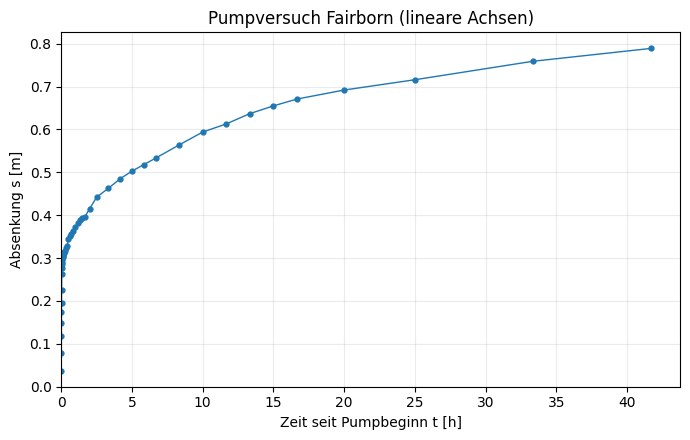

In [2]:
fig, ax = plt.subplots()
ax.plot(time_s/3600, drawdown_m, 'o-', ms=3.5, lw=1, color='tab:blue')
ax.set(xlabel='Zeit seit Pumpbeginn t [h]', ylabel='Absenkung s [m]', title='Pumpversuch Fairborn (lineare Achsen)')
ax.set_xlim(left=0); ax.set_ylim(bottom=0); ax.grid(alpha=.25); fig.tight_layout(); plt.show()

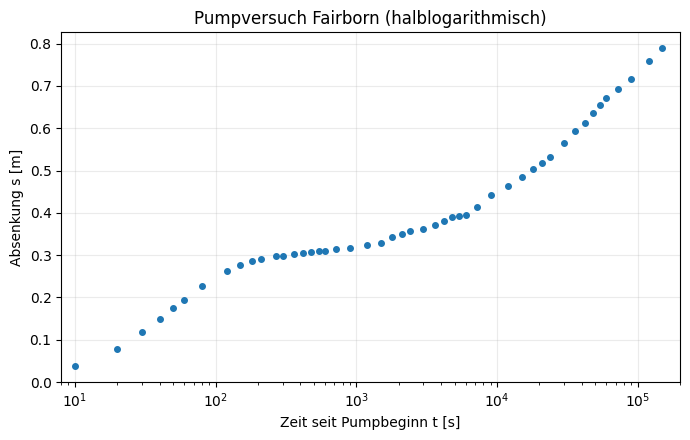

In [3]:
fig, ax = plt.subplots()
ax.semilogx(time_s, drawdown_m, 'o', ms=4, color='tab:blue')
ax.set(xlabel='Zeit seit Pumpbeginn t [s]', ylabel='Absenkung s [m]', title='Pumpversuch Fairborn (halblogarithmisch)')
ax.set_xlim(8,2e5); ax.set_ylim(bottom=0); ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## 3. Kazemi: Zwei parallele Geraden

Wie bei Cooper–Jacob werden Absenkungen s über log₁₀(t) aufgetragen. Die frühen und späten Geraden sollen **dieselbe Steigung** Δs (Absenkungszunahme je logarithmischer Dekade) besitzen. Die Schnittpunkte mit s=0 sind t₁ beziehungsweise t₂.

$$s_\mathrm{früh}(t)=\Delta s\,\log_{10}\!\left(\frac{t}{t_1}\right)$$

$$s_\mathrm{spät}(t)=\Delta s\,\log_{10}\!\left(\frac{t}{t_2}\right)$$

Der vertikale Abstand der Geraden beträgt:

$$\Delta s_v=\Delta s\,\log_{10}\!\left(\frac{t_2}{t_1}\right)$$

**Wichtig:** Die beiden Geraden sind *grafische Näherungen*. Eine Regression über alle Messpunkte wäre hier nicht sinnvoll, da die Übergangsphase keine Gerade darstellt. Auch getrennte Regressionen in sehr frühen und sehr späten Zeitfenstern liefern nicht notwendigerweise dieselbe Steigung.

### 3.1 Geraden anpassen

Als **Startwerte** verwenden wir die grafisch abgelesenen Größen aus der Musterlösung. Verändern Sie danach Δs, t₁ und t₂ und beurteilen Sie, wie gut beide Geraden zu den Messwerten passen. Die Anpassung ist bewusst **nicht automatisch optimiert**; die Entscheidung über frühe und späte Phase bleibt sichtbar.

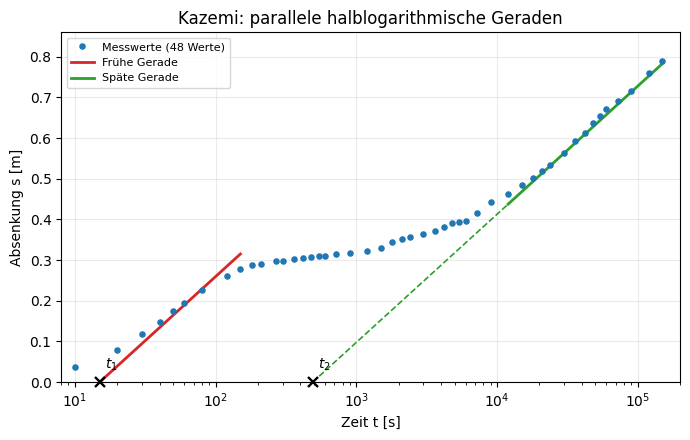

Δs = 0.315 m/decade; t1 = 15 s; t2 = 490 s


In [4]:
# Grafisch ermittelte Startwerte der Musterlösung
delta_s = 0.315  # m per log10 decade
t1 = 15.0       # s, early intercept
t2 = 490.0      # s, late intercept

def straight_line(t, t_zero, slope):
    return slope * np.log10(np.asarray(t)/t_zero)

# Gezeigte Anpassungsbereiche; illustrativ und veränderbar
t_early = np.geomspace(15, 150, 120)
t_late = np.geomspace(12000, 150000, 120)
t_early_ext = np.geomspace(t1, 15, 4) if t1<15 else np.array([t1])
t_late_ext = np.geomspace(t2, 12000, 100)
fig, ax = plt.subplots()
ax.semilogx(time_s, drawdown_m, 'o', ms=3.7, color='tab:blue', label='Messwerte (48 Werte)', zorder=3)
ax.semilogx(t_early, straight_line(t_early,t1,delta_s), '-', lw=2, color='tab:red', label='Frühe Gerade')
ax.semilogx(t_late, straight_line(t_late,t2,delta_s), '-', lw=2, color='tab:green', label='Späte Gerade')
ax.semilogx(t_late_ext, straight_line(t_late_ext,t2,delta_s), '--', lw=1.2, color='tab:green')
ax.plot([t1,t2],[0,0],'kx',ms=7,mew=1.7,clip_on=False,zorder=5)
ax.annotate(r'$t_1$',(t1,0),xytext=(4,10),textcoords='offset points')
ax.annotate(r'$t_2$',(t2,0),xytext=(4,10),textcoords='offset points')
ax.set(xlabel='Zeit t [s]', ylabel='Absenkung s [m]', title='Kazemi: parallele halblogarithmische Geraden')
ax.set_xlim(8,2e5); ax.set_ylim(0,.86); ax.grid(alpha=.25); ax.legend(fontsize=8,loc='upper left')
fig.tight_layout(); plt.show()
print(f"Δs = {delta_s:.3f} m/decade; t1 = {t1:g} s; t2 = {t2:g} s")

## 4. Hydraulische Parameter berechnen

Aus der Geradensteigung Δs ergibt sich die **Kluft-Transmissivität**:

$$T_f=\frac{2{,}30\,Q}{4\pi\,\Delta s}$$

Hierbei ist Q in m³/s einzusetzen. Aus den Nullschnittpunkten folgen die **Kluftspeicherung** S_f und die Summe aus Kluft- und Matrixspeicherung:

$$S_f=\frac{2{,}25\,T_f\,t_1}{r^2}$$

$$S_f+\beta S_m=\frac{2{,}25\,T_f\,t_2}{r^2}$$

Mit β=1 ergibt sich S_m. Der Anteil der Kluftspeicherung am Gesamtspeicher ist:

$$\omega=\frac{S_f}{S_f+\beta S_m}=\frac{t_1}{t_2}=10^{-\Delta s_v/\Delta s}$$

Die Parameter S_f, S_m und ω sind dimensionslos.

In [5]:
delta_s_v = delta_s * np.log10(t2/t1)
T_f = np.log(10) * Q / (4*np.pi*delta_s)
S_f = 2.25 * T_f*t1/r**2
S_total = 2.25 * T_f*t2/r**2
S_m = (S_total-S_f)/beta
omega = t1/t2
assert 0 < omega < 1 and S_m > 0
print(f"T_f = {T_f:.4e} m²/s")
print(f"S_f = {S_f:.4e}")
print(f"S_m = {S_m:.4e}")
print(f"omega = {omega:.4f}")
print(f"Δs_v = {delta_s_v:.3f} m")
print(f"Cross-check: 10^(-Δs_v/Δs) = {10**(-delta_s_v/delta_s):.4f}")

T_f = 3.9631e-02 m²/s
S_f = 2.7018e-03
S_m = 8.5556e-02
omega = 0.0306
Δs_v = 0.477 m
Cross-check: 10^(-Δs_v/Δs) = 0.0306


## 5. Vergleich mit der Musterlösung und Diskussion

Die Musterlösung nennt näherungsweise T_f=3,96×10⁻² m²/s, S_f=2,7×10⁻³, S_m=0,085 und ω=0,03. Aufgrund der **grafischen Ablesung** und der gerundeten Faktoren (2,30 und 2,25) sind kleine Unterschiede zu erwarten.

**Fragen zur Diskussion:** Warum ist S_m deutlich größer als S_f? Wie verändert sich S_m, wenn die späte Gerade nach rechts verschoben wird? Warum ist die Wahl paralleler Geraden eine Näherung?

**Einschränkungen:** Brunnen- und Aquifereffekte, die nicht im idealisierten Doppel-Porositäts-Modell enthalten sind, können ebenfalls die Kurvenform beeinflussen. Außerdem sind die historischen Daten und die Herkunft der Messreihe nicht unabhängig dokumentiert.

### 5.1 Empfindlichkeit der Geradenwahl (optional)

Eine kleine Änderung der abgelesenen Werte kann die Speicherkoeffizienten merklich beeinflussen. Die folgenden **Szenarien sind keine neuen Fits**, sondern illustrieren nur die Empfindlichkeit gegenüber der Geradenlage.

In [6]:
def kazemi_parameters(slope, early_intercept, late_intercept):
    tf = np.log(10)*Q/(4*np.pi*slope)
    sf = 2.25*tf*early_intercept/r**2
    sm = (2.25*tf*late_intercept/r**2-sf)/beta
    return tf, sf, sm, early_intercept/late_intercept

for label, slope, te, tl in [
    ("Baseline", 0.315, 15, 490),
    ("t1 -20%", 0.315, 12, 490),
    ("t2 +20%", 0.315, 15, 588),
    ("slope +10%", 0.3465, 15, 490),
]:
    tf, sf, sm, w = kazemi_parameters(slope,te,tl)
    print(f"{label:12s} T_f={tf:.4f} m²/s, S_f={sf:.4f}, S_m={sm:.4f}, ω={w:.3f}")

Baseline     T_f=0.0396 m²/s, S_f=0.0027, S_m=0.0856, ω=0.031
t1 -20%      T_f=0.0396 m²/s, S_f=0.0022, S_m=0.0861, ω=0.024
t2 +20%      T_f=0.0396 m²/s, S_f=0.0027, S_m=0.1032, ω=0.026
slope +10%   T_f=0.0360 m²/s, S_f=0.0025, S_m=0.0778, ω=0.031


## 6. Quellen

- Kruseman, G. P. & de Ridder, N. A. (1994): *Analysis and Evaluation of Pumping Test Data*, 2nd ed., ILRI Publication 47.
- Kazemi, H. (1969): *Pressure Transient Analysis of Naturally Fractured Reservoirs with Uniform Fracture Distribution*. *Society of Petroleum Engineers Journal*, **9**(4), 451–462. https://doi.org/10.2118/2156-A
- Kazemi, H., Seth, M. S. & Thomas, G. W. (1969): *The Interpretation of Interference Tests in Naturally Fractured Reservoirs with Uniform Fracture Distribution*. *Society of Petroleum Engineers Journal*, **9**(4), 463–472. https://doi.org/10.2118/2156-B